<a href="https://colab.research.google.com/github/LetheeshBalaji/24ADI003-24BAD063/blob/main/24BAD063_Exp_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Part A: Dataset preparation
This loads the IMDB dataset, converts reviews into numerical sequences, and pads them to a fixed length.
Roll Number :24BAD063


In [1]:

# Experiment No. 6: LSTM for Sentiment Analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)

# Replace with your actual roll number
ROLL_NO = "YOUR_ROLL_NUMBER"

# Load IMDB dataset
VOCAB_SIZE = 10000
MAX_LEN = 200

(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=VOCAB_SIZE
)

print("Roll Number:", ROLL_NO)
print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))
print("Sample encoded review:", x_train[0][:20])
print("Sample sentiment:", y_train[0])

# Pad sequences to equal length
x_train = pad_sequences(
    x_train, maxlen=MAX_LEN, padding="post", truncating="post"
)
x_test = pad_sequences(
    x_test, maxlen=MAX_LEN, padding="post", truncating="post"
)

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)
print("Positive reviews:", np.sum(y_train == 1))
print("Negative reviews:", np.sum(y_train == 0))


17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Roll Number: YOUR_ROLL_NUMBER
Training samples: 25000
Testing samples: 25000
Sample encoded review: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]
Sample sentiment: 1
Training shape: (25000, 200)
Testing shape: (25000, 200)
Positive reviews: 12500
Negative reviews: 12500


Part B: Build the LSTM model
Roll Number : 24BAD063

In [2]:

model = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=64, input_length=MAX_LEN),
    LSTM(64, dropout=0.2),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Part C: Train and evaluate the model
Roll Number : 24BAD063

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 67s 386ms/step - accuracy: 0.5254 - loss: 0.6931 - val_accuracy: 0.5226 - val_loss: 0.6913
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 49s 313ms/step - accuracy: 0.5975 - loss: 0.6642 - val_accuracy: 0.7184 - val_loss: 0.5929
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 47s 299ms/step - accuracy: 0.5344 - loss: 0.6957 - val_accuracy: 0.5106 - val_loss: 0.6924
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 49s 312ms/step - accuracy: 0.5795 - loss: 0.6645 - val_accuracy: 0.6054 - val_loss: 0.6387
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 58s 369ms/step - accuracy: 0.6891 - loss: 0.5757 - val_accuracy: 0.8262 - val_loss: 0.4504
Training Accuracy: 0.8489
Training Loss: 0.4063
Test Accuracy: 0.8037
Test Loss: 0.4769
Accuracy: 0.80368
Precision: 0.8416126709863211
Recall: 0.74816
F1-score: 0.7921395900389633

Classification Report:
              precision    recall  f1-score   support

    Negative       0.77      0.86      0.81     12500
    Positive       0.84      0.75   

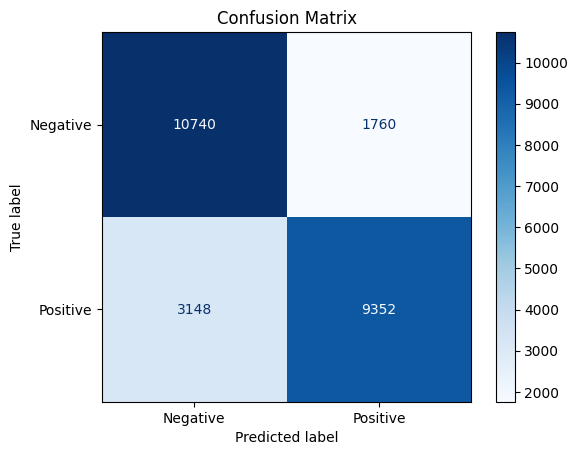

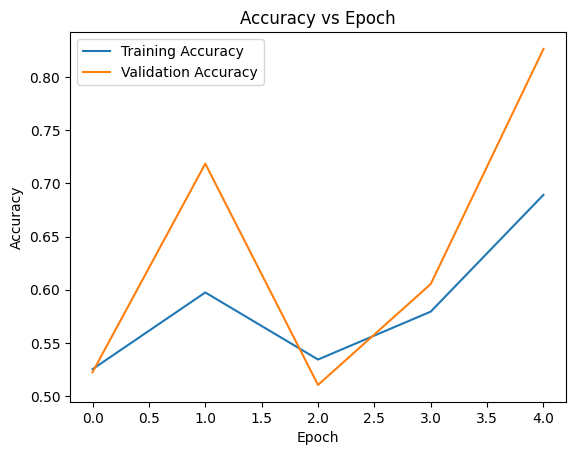

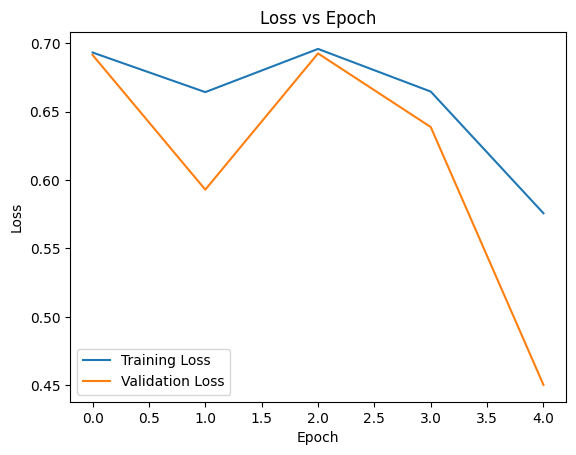

In [3]:

# Train the model
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)

# Training and validation accuracy/loss
train_loss, train_acc = model.evaluate(x_train, y_train, verbose=0)
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)

print(f"Training Accuracy: {train_acc:.4f}")
print(f"Training Loss: {train_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Loss: {test_loss:.4f}")

# Predict sentiment for test data
y_prob = model.predict(x_test, batch_size=128, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

# Evaluation metrics
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred, zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Negative", "Positive"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
).plot(cmap="Blues")

plt.title("Confusion Matrix")
plt.show()

# Accuracy vs Epoch
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Epoch")
plt.legend()
plt.show()

# Loss vs Epoch
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss vs Epoch")
plt.legend()
plt.show()


Part D: Predict sentiment for new reviews
The IMDB dataset provides integer sequences, so use the same IMDB word index to
encode new reviews.
Roll  Number : 24BAD063

In [4]:

# Convert new review text into IMDB-compatible sequences
word_index = imdb.get_word_index()

def encode_review(text):
    words = text.lower().split()
    sequence = []

    for word in words:
        # IMDB reserves index 0 for padding, 1 for start,
        # and 2 for unknown words.
        index = word_index.get(word, 2) + 3
        if index >= VOCAB_SIZE:
            index = 2
        sequence.append(index)

    # Add start token and pad/truncate
    sequence = [1] + sequence
    return pad_sequences(
        [sequence], maxlen=MAX_LEN,
        padding="post", truncating="post"
    )

def predict_sentiment(review):
    encoded = encode_review(review)
    probability = float(model.predict(encoded, verbose=0)[0][0])

    sentiment = "Positive" if probability >= 0.5 else "Negative"

    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print(f"Positive probability: {probability:.4f}")
    print("-" * 50)

# Test multiple reviews
predict_sentiment("This movie was fantastic and the acting was excellent")
predict_sentiment("The movie was boring and the story was terrible")
predict_sentiment("I enjoyed the film and would recommend it")
predict_sentiment("The film was disappointing and a waste of time")


1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Review: This movie was fantastic and the acting was excellent
Predicted sentiment: Negative
Positive probability: 0.4472
--------------------------------------------------
Review: The movie was boring and the story was terrible
Predicted sentiment: Negative
Positive probability: 0.2985
--------------------------------------------------
Review: I enjoyed the film and would recommend it
Predicted sentiment: Positive
Positive probability: 0.5725
--------------------------------------------------
Review: The film was disappointing and a waste of time
Predicted sentiment: Negative
Positive probability: 0.2958
--------------------------------------------------
